In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import optax

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

# Functions with different n values

In [4]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [5]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [6]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_626_samples_n_different.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (626, 12)
Number of samples: 626
Number of parameters per sample: 12


# Stability check

In [12]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [13]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 626 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 626 samples for analysis


In [14]:
# Analyze stability

stability_results_all = {}

n_r = 2.333
n_b = 0.9
n_g = 2.0626
n_y = 1.562


stability_results = []
max_real_parts = []
min_real_parts = []
all_eigenvalues = []

for i in range(n_samples_to_analyze):
    theta_star = theta_subset[i, :]

    # Get fixed point outputs with new n values
    try:
        r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)

        # Construct state vector s* = [r, g, y]
        s_star = jnp.concatenate([r_star, g_star, y_star])

        # Verify it's a fixed point
        s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
        s_error = jnp.linalg.norm(s_prime - s_star)

        if s_error > 1e-3:
            print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

        # Compute stability
        result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
        stability_results.append(result)

        max_real_parts.append(np.max(result['real_parts']))
        min_real_parts.append(np.min(result['real_parts']))
        all_eigenvalues.append(result['eigenvalues'])

    except Exception as e:
        print(f"  Sample {i+1}: Error - {e}")
        continue


KeyboardInterrupt: 

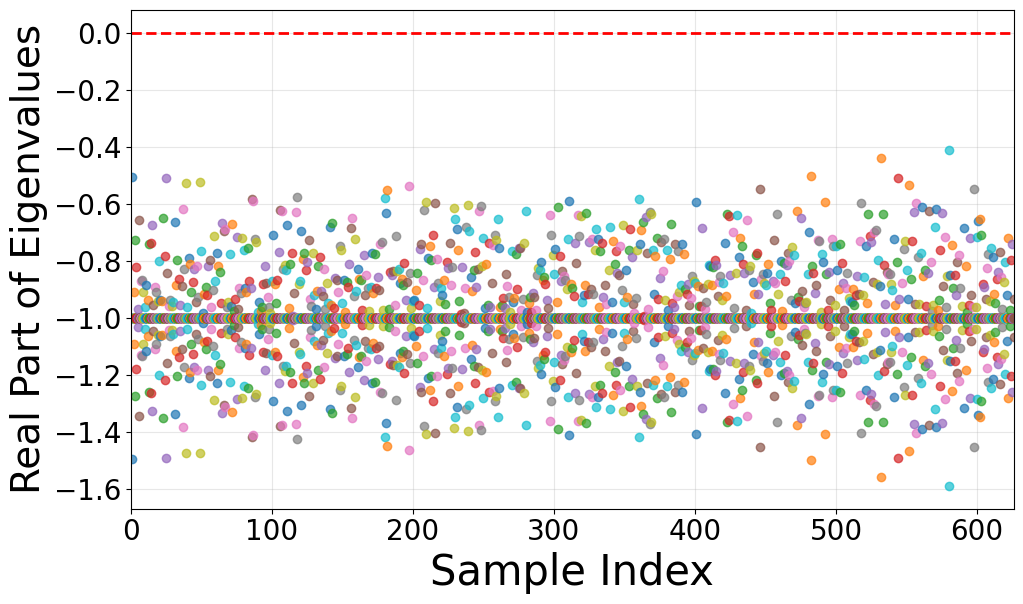


STABILITY SUMMARY

Stable samples: 626/626 (100.0%)


In [8]:
# visualise stability results
fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))

# use actual number of samples
actual_no_samples = len(stability_results)
for i in range(actual_no_samples):
    real_parts = stability_results[i]['real_parts']
    ax1.plot([i+1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i+1}' if i < 5 else '')
ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
ax1.set_xlabel('Sample Index', fontsize=30)
ax1.set_ylabel('Real Part of Eigenvalues', fontsize=28)
actual_no_samples = len(stability_results)
ax1.set_xlim(0, actual_no_samples)
ax1.grid(True, alpha=0.3)

stable_count = sum(1 for r in stability_results if r['is_stable'])
unstable_count = actual_no_samples - stable_count

plt.tight_layout()
plt.tick_params(axis='both', direction='out')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.savefig('Figures/stability.eps')
plt.show()

# print summary
print("\n" + "=" * 70)
print("STABILITY SUMMARY")
print("=" * 70)
print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100*stable_count/actual_no_samples:.1f}%)")

In [15]:
# remove unstable theta
theta_opt = np.array(theta_opt)

# Identify unstable samples from stability_results
remove_row = [i for i, r in enumerate(stability_results) if not r['is_stable']]

max_index = theta_opt.shape[0] - 1
valid_remove_row = [i for i in remove_row if 0 <= i <= max_index]

for i in sorted(valid_remove_row, reverse=True):
    theta_opt = np.delete(theta_opt, i, axis=0)

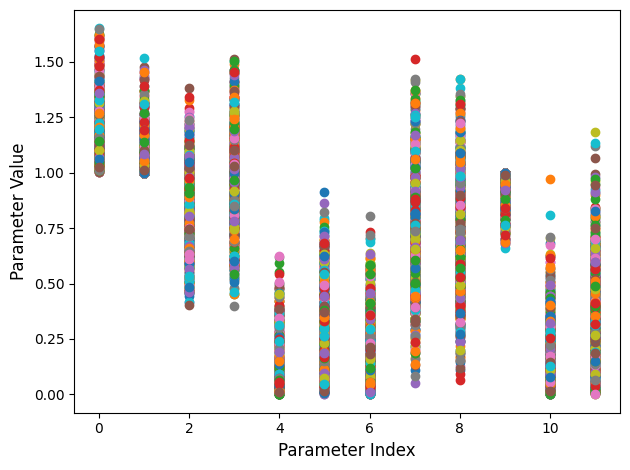

In [16]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


# Compute Hessian

Processing 626 samples...
  Sample 1/626...
  Sample 101/626...
  Sample 201/626...
  Sample 301/626...
  Sample 401/626...
  Sample 501/626...
  Sample 601/626...
Completed processing 626 samples


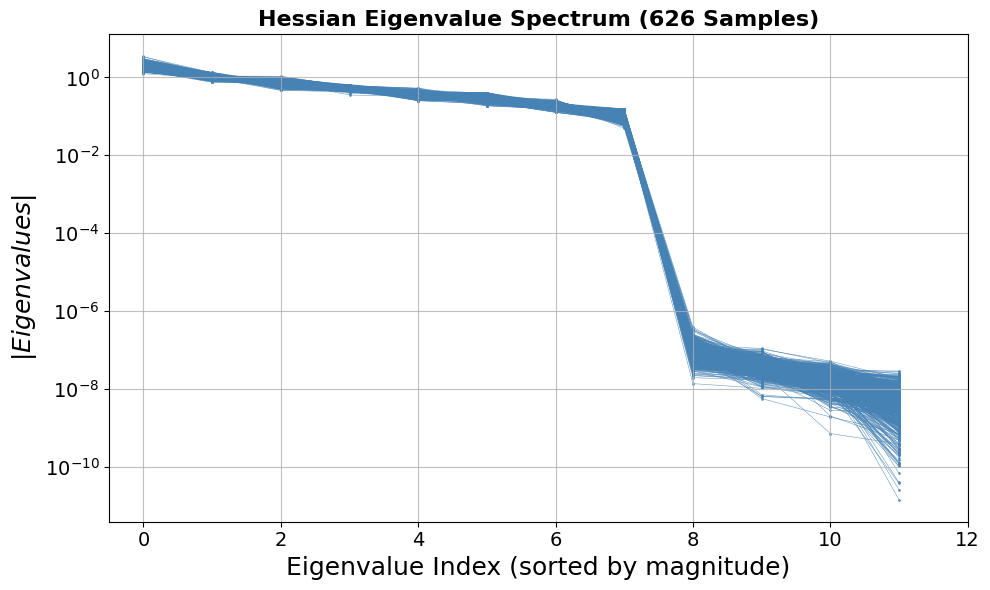

In [17]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [18]:

threshold = 1e-5  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)

    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)

    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)

    return eigenvectors_subspace2

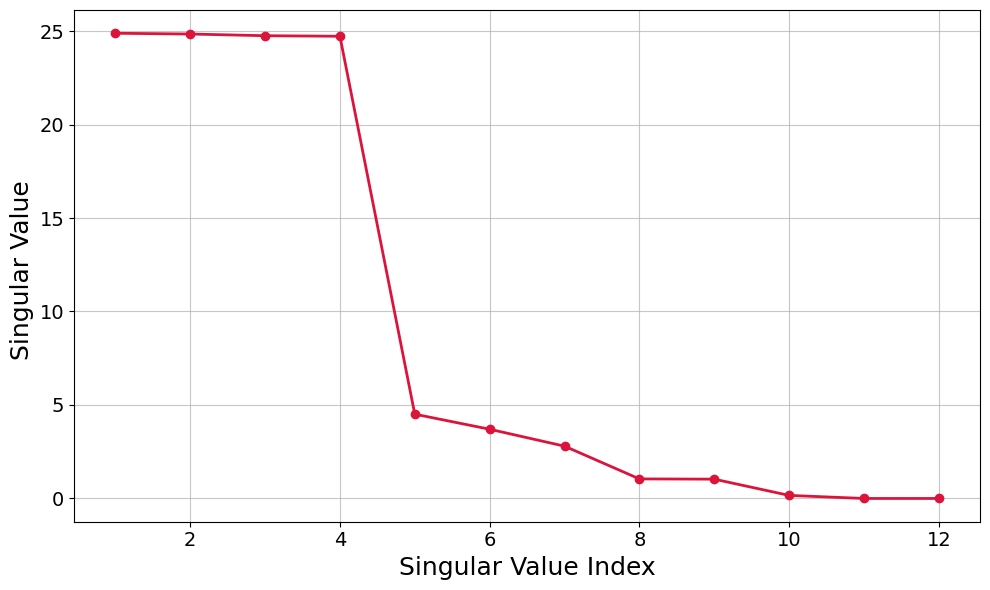

In [19]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(S)+1), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=18)
plt.ylabel('Singular Value ', fontsize=18)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

In [20]:
Vt[:4].shape # orthonormal rows
Vt[:4].T.shape # orthonormal columns

(12, 4)

In [24]:
Vt[:4]
np.savetxt('vectors_for_guillaume.txt', Vt[:4].T, delimiter=',')

In [15]:
def sparse_rotation(U):

    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))


    # Initialise Adam optimizer
    key = jax.random.PRNGKey(0)
    key, subkey = jax.random.split(key)
    k = U.shape[1]  # Number of columns
    qtilde = jax.random.normal(subkey, (k, k))  # Fixed: should be (k, k) not (r, k)
    optimizer = optax.adam(learning_rate=0.004, eps=1e-4)
    opt_state = optimizer.init(qtilde)


    # Create value_and_grad function
    loss_value_and_grad = jax.value_and_grad(loss)

    # Optimization loop
    for iteration in range(10000):
        loss_value, grads = loss_value_and_grad(qtilde)
        updates, opt_state = optimizer.update(grads, opt_state)
        qtilde = optax.apply_updates(qtilde, updates)

        if iteration % 1000 == 0:
            print(f"Iteration {iteration}, Loss: {float(loss_value)}")

    # Get optimized q
    q_opt,_ = jnp.linalg.qr(qtilde)

    U_sparse = U @ q_opt
    return U_sparse

#U_sparse = sparse_rotation(Vt[:4].T)

In [16]:
def varimax(U, iterations=1000, tol=1e-8):
    n, k = U.shape
    # Initialize Q as an identity matrix
    Q = np.eye(k)
    
    # Optional: Normalizing U (Kaiser Normalization)
    row_norms = np.sqrt(np.sum(U**2, axis=1, keepdims=True))
    U_norm = U / row_norms

    for i in range(iterations):
        Q_old = Q.copy()
        
        # 1. Rotate the basis: U_tilde = U @ Q
        U_tilde = U_norm @ Q
        
        # 2. Compute the Varimax objective gradient
        # (U_tilde**3) is the derivative of the L4 norm (sum of squared variances)
        A = U_norm.T @ (U_tilde**3 - (1.0/n) * U_tilde @ np.diag(np.sum(U_tilde**2, axis=0)))
        
        # 3. Use SVD to find the nearest orthogonal matrix (Procrustes Step)
        L, S, M_h = np.linalg.svd(A)
        Q = L @ M_h
        
        # Check convergence
        if np.abs(np.abs(np.diag(Q @ Q_old.T)).sum() - k) < tol:
            break

    # Final sparse representation
    U_sparse = (U_norm @ Q) * row_norms
    return U_sparse, Q

#U_sparse, Q = varimax(Vt[:4].T)

In [17]:
U_1, Q = varimax(Vt[:4].T)
U_2 = sparse_rotation(Vt[:4].T)

Iteration 0, Loss: 0.20072558522224426
Iteration 1000, Loss: 0.1548072099685669
Iteration 2000, Loss: 0.1548178791999817
Iteration 3000, Loss: 0.15481486916542053
Iteration 4000, Loss: 0.15488168597221375
Iteration 5000, Loss: 0.15481367707252502
Iteration 6000, Loss: 0.15484249591827393
Iteration 7000, Loss: 0.15479782223701477
Iteration 8000, Loss: 0.154798686504364
Iteration 9000, Loss: 0.15480616688728333


In [18]:
basis_prod = U_1.T @ U_2
basis_prod.shape

(4, 4)

In [19]:
U_svd, S_svd, Vt_svd = np.linalg.svd(basis_prod)
S_svd


array([1.0000004 , 1.0000001 , 1.        , 0.99999994], dtype=float32)

In [20]:
U_sparse = U_1

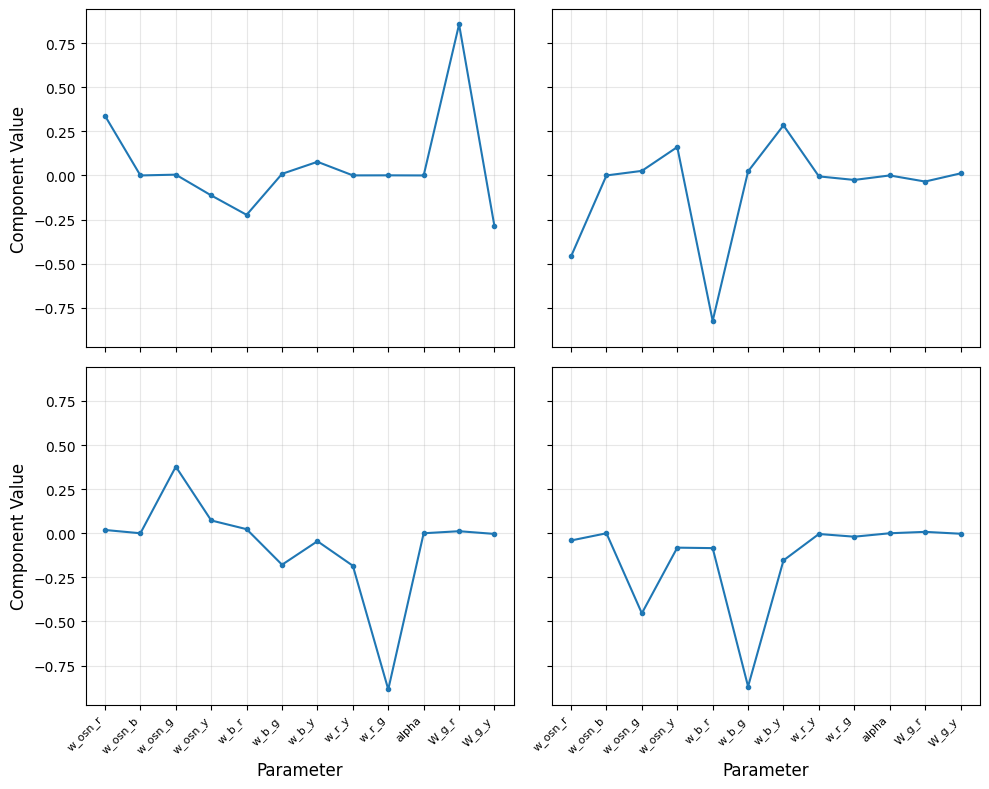

In [21]:

M = U_sparse

# Create parameter labels in the correct order
param_labels = [
    'w_osn_r',
    'w_osn_b',
    'w_osn_g',
    'w_osn_y',
    'w_b_r',
    'w_b_g',
    'w_b_y',
    'w_r_y',
    'w_r_g',
    'alpha',
    'W_g_r',
    'W_g_y'
]

# Sort components by sparsity (sum of absolute values)
M_sums = np.abs(M).sum(0)
sorting_ind = np.argsort(M_sums)[::-1]
M_plot = M[:, sorting_ind]

# Get number of components
n_components = M_plot.shape[1]

# Calculate grid size
n_rows, n_cols = 2, 2
fig, ax = plt.subplots(figsize=(10, 8), nrows=n_rows, ncols=n_cols, sharex=True, sharey=True)

# Flatten axes array for easier indexing
ax = ax.flatten()

# Plot all components
for i in range(n_components):
    ax[i].plot(M_plot[:, i], '.-', label=f'Component {sorting_ind[i]+1} (sorted {i+1})')
    ax[i].set_xticks(range(len(param_labels)))
    ax[i].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    ax[i].grid(True, alpha=0.3)


# Hide unused subplots
for i in range(n_components, n_rows * n_cols):
    ax[i].axis('off')

# Set labels for bottom row
for col in range(n_cols):
    row_idx = (n_rows - 1) * n_cols + col
    if row_idx < n_components:
        ax[row_idx].set_xlabel('Parameter', fontsize=12)

# Set labels for left column
for row in range(n_rows):
    col_idx = row * n_cols
    if col_idx < n_components:
        ax[col_idx].set_ylabel('Component Value', fontsize=12)

plt.tight_layout()
plt.show()

# Step in Delta Theta

Delta_theta 0, Epsilon 0, Sample 0
Delta_theta 0, Epsilon 0, Sample 1
Delta_theta 0, Epsilon 1, Sample 0
Delta_theta 0, Epsilon 1, Sample 1
Delta_theta 0, Epsilon 2, Sample 0
Delta_theta 0, Epsilon 2, Sample 1
Delta_theta 0, Epsilon 3, Sample 0
Delta_theta 0, Epsilon 3, Sample 1
Delta_theta 0, Epsilon 4, Sample 0
Delta_theta 0, Epsilon 4, Sample 1
Delta_theta 0, Epsilon 5, Sample 0
Delta_theta 0, Epsilon 5, Sample 1
Delta_theta 0, Epsilon 6, Sample 0
Delta_theta 0, Epsilon 6, Sample 1
Delta_theta 0, Epsilon 7, Sample 0
Delta_theta 0, Epsilon 7, Sample 1
Delta_theta 0, Epsilon 8, Sample 0
Delta_theta 0, Epsilon 8, Sample 1
Delta_theta 1, Epsilon 0, Sample 0
Delta_theta 1, Epsilon 0, Sample 1
Delta_theta 1, Epsilon 1, Sample 0
Delta_theta 1, Epsilon 1, Sample 1
Delta_theta 1, Epsilon 2, Sample 0
Delta_theta 1, Epsilon 2, Sample 1
Delta_theta 1, Epsilon 3, Sample 0
Delta_theta 1, Epsilon 3, Sample 1
Delta_theta 1, Epsilon 4, Sample 0
Delta_theta 1, Epsilon 4, Sample 1
Delta_theta 1, Epsil

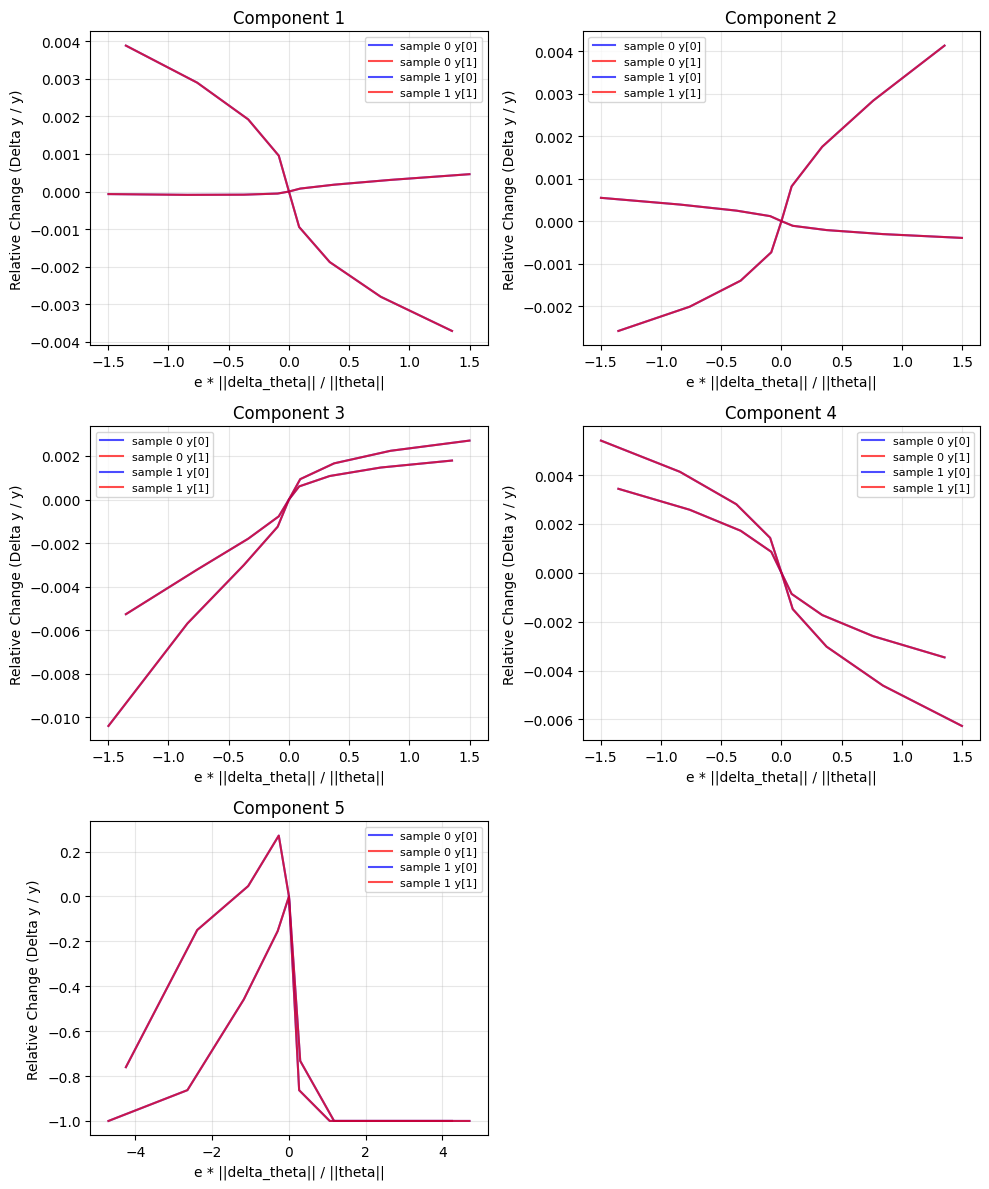

In [22]:
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 2  # Number of samples to process

theta_opt_subset = jnp.array(theta_opt[:n_samples])

key = jax.random.PRNGKey(0)
random_col = jax.random.normal(key, (U_sparse.shape[0], 1))
U_sparse_rand = jnp.hstack([U_sparse, random_col])

fig, ax = plt.subplots(3, 2, figsize=(10, 12))
ax = ax.flatten()

# Baseline y at epsilon = 0 (unperturbed theta)
y_baseline = []
for j in range(n_samples):
    theta_row = np.array(theta_opt_subset[j])
    r, g, b, y = mitral_output(theta_row, x, m, n_r, n_b, n_g, n_y)
    y_baseline.append(np.array(y))
y_baseline = np.array(y_baseline)  # shape (n_samples, 2)

for k in range(5):
    y_save = []
    for i in range(len(e)):
        theta_step = theta_opt_subset + e[i] * U_sparse_rand[:, k]
        y_samples = []
        for j in range(theta_step.shape[0]):
            theta_row = np.array(theta_step[j])
            r, g, b, y = mitral_output(theta_row, x, m, n_r, n_b, n_g, n_y)
            y_samples.append(np.array(y))
            print(f"Delta_theta {k}, Epsilon {i}, Sample {j}")
        y_save.append(np.array(y_samples))
    y_array = np.array(y_save)
    for sample_idx in range(n_samples):
        y0 = y_baseline[sample_idx, 0]
        y1 = y_baseline[sample_idx, 1]
        rel0 = np.where(np.abs(y0) > 1e-12, (y_array[:, sample_idx, 0] - y0) / y0, y_array[:, sample_idx, 0] - y0)
        rel1 = np.where(np.abs(y1) > 1e-12, (y_array[:, sample_idx, 1] - y1) / y1, y_array[:, sample_idx, 1] - y1)
        norm_theta_j = np.linalg.norm(np.array(theta_opt_subset[sample_idx]))
        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * np.array(U_sparse_rand[:, k])) / norm_theta_j) for i in range(len(e))])
        ax[k].plot(theta_ratio, rel0, color='blue', alpha=0.7, label=f'sample {sample_idx} y[0]')
        ax[k].plot(theta_ratio, rel1, color='red', alpha=0.7, label=f'sample {sample_idx} y[1]')
    ax[k].set_xlabel('e * ||delta_theta|| / ||theta||')
    ax[k].set_ylabel('Relative Change (Delta y / y)')
    ax[k].set_title(f'Component {k+1}')
    ax[k].grid(True, alpha=0.3)
    ax[k].legend(fontsize=8)
ax[5].set_visible(False)
plt.tight_layout()
plt.show()

Delta_theta 0, Epsilon 0, Sample 0
Delta_theta 0, Epsilon 0, Sample 1
Delta_theta 0, Epsilon 0, Sample 2
Delta_theta 0, Epsilon 1, Sample 0
Delta_theta 0, Epsilon 1, Sample 1
Delta_theta 0, Epsilon 1, Sample 2
Delta_theta 0, Epsilon 2, Sample 0
Delta_theta 0, Epsilon 2, Sample 1
Delta_theta 0, Epsilon 2, Sample 2
Delta_theta 0, Epsilon 3, Sample 0
Delta_theta 0, Epsilon 3, Sample 1
Delta_theta 0, Epsilon 3, Sample 2
Delta_theta 0, Epsilon 4, Sample 0
Delta_theta 0, Epsilon 4, Sample 1
Delta_theta 0, Epsilon 4, Sample 2
Delta_theta 0, Epsilon 5, Sample 0
Delta_theta 0, Epsilon 5, Sample 1
Delta_theta 0, Epsilon 5, Sample 2
Delta_theta 0, Epsilon 6, Sample 0
Delta_theta 0, Epsilon 6, Sample 1
Delta_theta 0, Epsilon 6, Sample 2
Delta_theta 0, Epsilon 7, Sample 0
Delta_theta 0, Epsilon 7, Sample 1
Delta_theta 0, Epsilon 7, Sample 2
Delta_theta 0, Epsilon 8, Sample 0
Delta_theta 0, Epsilon 8, Sample 1
Delta_theta 0, Epsilon 8, Sample 2
Delta_theta 1, Epsilon 0, Sample 0
Delta_theta 1, Epsil

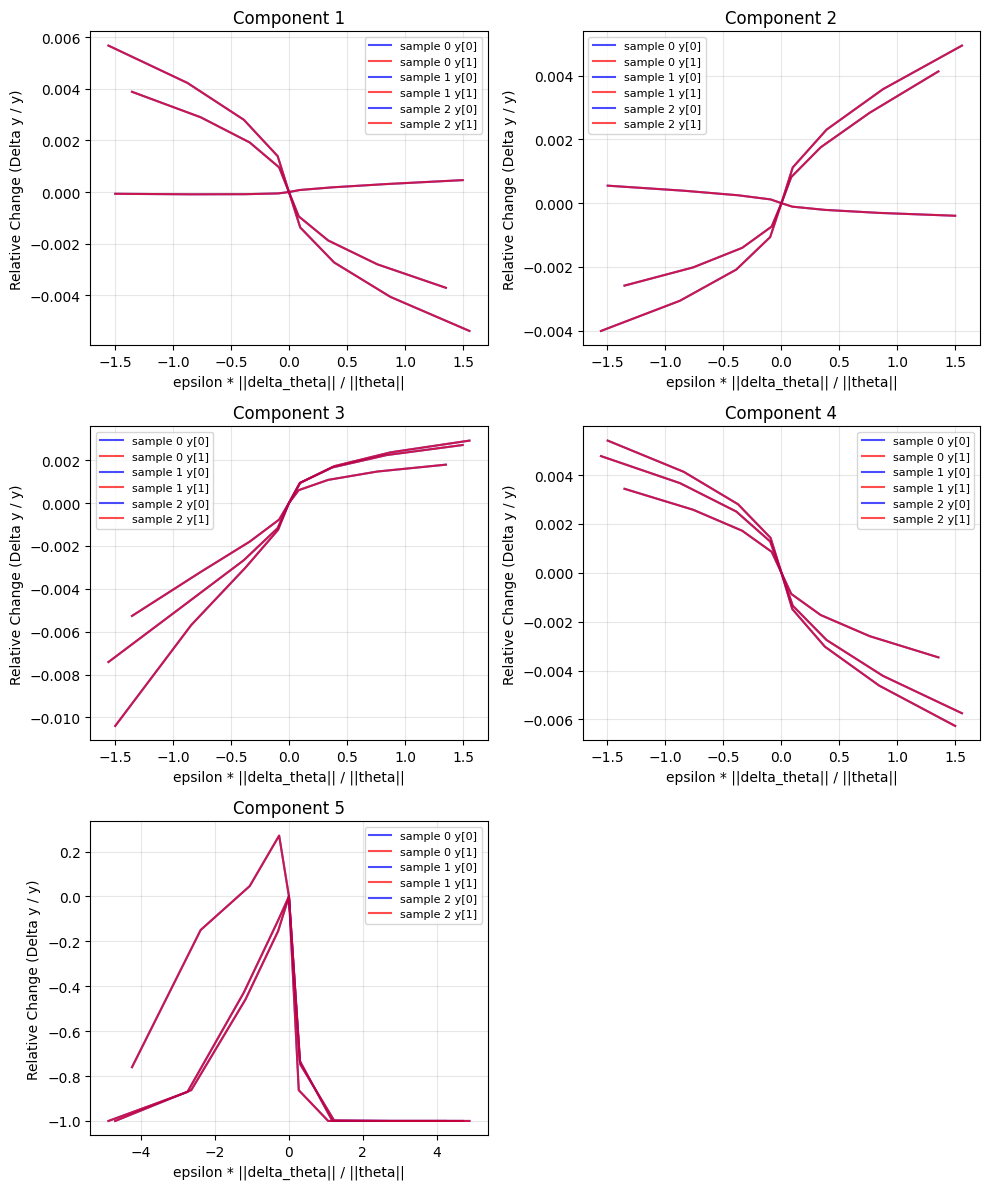

In [ ]:
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 3  # Number of samples to process

theta_opt_subset = jnp.array(theta_opt[:n_samples])

key = jax.random.PRNGKey(0)
random_col = jax.random.normal(key, (U_sparse.shape[0], 1))
U_sparse_rand = jnp.hstack([U_sparse, random_col])

fig, ax = plt.subplots(3, 2, figsize=(10, 12))
ax = ax.flatten()

# Baseline y at epsilon = 0 (unperturbed theta)
y_baseline = []
for j in range(n_samples):
    theta_row = np.array(theta_opt_subset[j])
    r, g, b, y = mitral_output(theta_row, x, m, n_r, n_b, n_g, n_y)
    y_baseline.append(np.array(y))
y_baseline = np.array(y_baseline)  # shape (n_samples, 2)

for k in range(5):
    y_save = []
    for i in range(len(e)):
        theta_step = theta_opt_subset + e[i] * U_sparse_rand[:, k]
        y_samples = []
        for j in range(theta_step.shape[0]):
            theta_row = np.array(theta_step[j])
            r, g, b, y = mitral_output(theta_row, x, m, n_r, n_b, n_g, n_y)
            y_samples.append(np.array(y))
            print(f"Delta_theta {k}, Epsilon {i}, Sample {j}")
        y_save.append(np.array(y_samples))
    y_array = np.array(y_save)
    for sample_idx in range(n_samples):
        y0 = y_baseline[sample_idx, 0]
        y1 = y_baseline[sample_idx, 1]
        rel0 = np.where(np.abs(y0) > 1e-12, (y_array[:, sample_idx, 0] - y0) / y0, y_array[:, sample_idx, 0] - y0)
        rel1 = np.where(np.abs(y1) > 1e-12, (y_array[:, sample_idx, 1] - y1) / y1, y_array[:, sample_idx, 1] - y1)
        norm_theta_j = np.linalg.norm(np.array(theta_opt_subset[sample_idx]))
        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * np.array(U_sparse_rand[:, k])) / norm_theta_j) for i in range(len(e))])
        ax[k].plot(theta_ratio, rel0, color='blue', alpha=0.7, label=f'sample {sample_idx} y[0]')
        ax[k].plot(theta_ratio, rel1, color='red', alpha=0.7, label=f'sample {sample_idx} y[1]')
    ax[k].set_xlabel('epsilon * ||delta_theta|| / ||theta||')
    ax[k].set_ylabel('Relative Change (Delta y / y)')
    ax[k].set_title(f'Component {k+1}')
    ax[k].grid(True, alpha=0.3)
    ax[k].legend(fontsize=8)
ax[5].set_visible(False)
plt.tight_layout()
plt.show()